In [3]:
!pip install silence_tensorflow -q

import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf

# Disable XLA (removes all CUDA timer warnings)
tf.config.optimizer.set_jit(False)

# Optional: reduce TensorFlow logging noise
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

import tensorflow as tf
from silence_tensorflow import silence_tensorflow
silence_tensorflow("INFO")

from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import mixed_precision

print("TensorFlow:", tf.__version__)
from tensorflow.keras.applications import EfficientNetB0, EfficientNetB4
from tensorflow.keras.applications.efficientnet import preprocess_input



TensorFlow: 2.19.0


In [4]:
mixed_precision.set_global_policy("mixed_float16")

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


In [5]:
base_dir = "/kaggle/input/datasets/kmader/rsna-bone-age"

train_csv_path = os.path.join(base_dir, "boneage-training-dataset.csv")
train_img_dir  = os.path.join(base_dir, "boneage-training-dataset", "boneage-training-dataset")

df = pd.read_csv(train_csv_path)

df["path"] = df["id"].map(lambda x: os.path.join(train_img_dir, f"{x}.png"))
df["gender"] = df["male"].map(lambda x: "male" if x else "female")
df["sex"] = df["gender"].map(lambda x: 1 if x == "male" else 0)

boneage_std = 2 * df["boneage"].std()
boneage_mean = df["boneage"].mean()
df["norm_age"] = (df["boneage"] - boneage_mean) / boneage_std

df.head()


,id,boneage,male,path,gender,sex,norm_age
0,1377,180,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,0.639590
1,1378,12,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-1.400135
2,1379,94,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-0.404555
3,1380,120,True,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,male,1,-0.088883
4,1381,82,False,/kaggle/input/datasets/kmader/rsna-bone-age/bo...,female,0,-0.550249


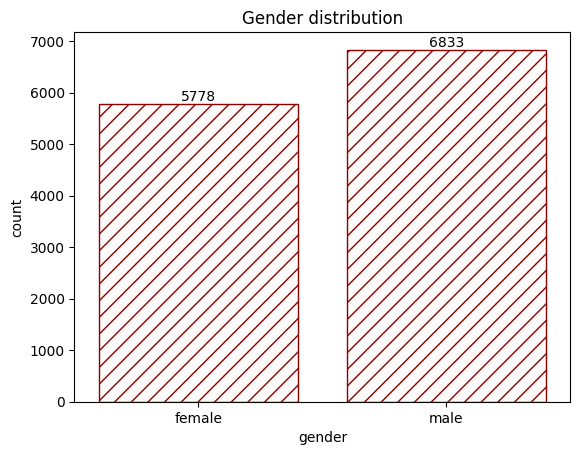

In [6]:
ax = sns.countplot(x=df['gender'], color="snow", hatch='//', edgecolor="darkred")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Gender distribution")
plt.show()


In [7]:
train_df, val_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["gender"]
)

len(train_df), len(val_df)


(10719, 1892)

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
])

def load_and_preprocess(image_path, sex, label, training=True):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = preprocess_input(img)

    if training:
        img = data_augmentation(img)

    sex = tf.cast(sex, tf.float32)
    sex = tf.expand_dims(sex, -1)

    label = tf.cast(label, tf.float32)

    return {"image_input": img, "gender_input": sex}, label

def make_dataset(dataframe, training=True):
    paths = dataframe["path"].values
    sexes = dataframe["sex"].values.astype("float32")
    labels = dataframe["norm_age"].values.astype("float32")

    ds = tf.data.Dataset.from_tensor_slices((paths, sexes, labels))

    if training:
        ds = ds.shuffle(buffer_size=len(dataframe))

    ds = ds.map(
        lambda p, s, y: load_and_preprocess(p, s, y, training=training),
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df, training=False)


I0000 00:00:1777900998.990596      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13571 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777900998.996783      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [9]:
def build_efficientnetb0_model():
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    gender_input = layers.Input(shape=(1,), name="gender_input")

    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input
    )

    # freeze most layers initially
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)

    g = layers.Dense(16, activation="relu")(gender_input)

    combined = layers.Concatenate()([x, g])

    z = layers.Dense(256, activation="relu")(combined)
    z = layers.Dropout(0.4)(z)
    z = layers.Dense(64, activation="relu")(z)
    output = layers.Dense(1, activation="linear", dtype="float32")(z)

    model = Model(inputs=[img_input, gender_input], outputs=output)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="mae",
        metrics=["mae"]
    )

    return model

model = build_efficientnetb0_model()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
callbacks = [
    EarlyStopping(monitor="val_mae", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.3, patience=3, verbose=1),
    ModelCheckpoint("efficientnetb0_base.h5", monitor="val_mae", save_best_only=True)
]

EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/25


I0000 00:00:1777901017.178974     145 service.cc:152] XLA service 0x7a504841b340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777901017.179018     145 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777901017.179025     145 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777901020.829463     145 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1777901060.271611     145 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - loss: 0.3145 - mae: 0.3145

335/335 ━━━━━━━━━━━━━━━━━━━━ 397s 975ms/step - loss: 0.3143 - mae: 0.3143 - val_loss: 0.1960 - val_mae: 0.1960 - learning_rate: 1.0000e-04
Epoch 2/25
333/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.2151 - mae: 0.2151

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.2150 - mae: 0.2150 - val_loss: 0.1723 - val_mae: 0.1723 - learning_rate: 1.0000e-04
Epoch 3/25
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1895 - mae: 0.1895

...

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1153 - mae: 0.1153 - val_loss: 0.1387 - val_mae: 0.1387 - learning_rate: 9.0000e-06
Epoch 18/25
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1117 - mae: 0.1117

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1117 - mae: 0.1117 - val_loss: 0.1380 - val_mae: 0.1380 - learning_rate: 9.0000e-06
Epoch 19/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1141 - mae: 0.1141 - val_loss: 0.1400 - val_mae: 0.1400 - learning_rate: 9.0000e-06
Epoch 20/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1129 - mae: 0.1129 - val_loss: 0.1384 - val_mae: 0.1384 - learning_rate: 9.0000e-06
Epoch 21/25
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1126 - mae: 0.1126
Epoch 21: ReduceLROnPlateau reducing learning rate to 2.6999998226528985e-06.
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1126 - mae: 0.1126 - val_loss: 0.1398 - val_mae: 0.1398 - learning_rate: 9.0000e-06
Epoch 22/25
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1120 - mae: 0.1120

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - loss: 0.1120 - mae: 0.1120 - val_loss: 0.1374 - val_mae: 0.1374 - learning_rate: 2.7000e-06
Epoch 23/25
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1126 - mae: 0.1126

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - loss: 0.1125 - mae: 0.1125 - val_loss: 0.1360 - val_mae: 0.1360 - learning_rate: 2.7000e-06
Epoch 24/25
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1108 - mae: 0.1108 - val_loss: 0.1367 - val_mae: 0.1367 - learning_rate: 2.7000e-06
Epoch 25/25
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1108 - mae: 0.1108

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1108 - mae: 0.1108 - val_loss: 0.1357 - val_mae: 0.1357 - learning_rate: 2.7000e-06


In [11]:
def denormalize_age(norm_age):
    return norm_age * boneage_std + boneage_mean
# --- Evaluate BEFORE fine-tuning ---
y_true_base = []
y_pred_base = []

for batch in val_ds:
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)
    y_true_base.extend(labels.numpy().flatten())
    y_pred_base.extend(preds.flatten())

y_true_base_months = denormalize_age(np.array(y_true_base))
y_pred_base_months = denormalize_age(np.array(y_pred_base))

base_mae_months = mean_absolute_error(y_true_base_months, y_pred_base_months)
print("EfficientNetB0 BASE MODEL Validation MAE (months):", base_mae_months)


EfficientNetB0 BASE MODEL Validation MAE (months): 11.175289934469548


In [12]:
for layer in model.layers[-20:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=3e-6),
    loss="mae",
    metrics=["mae"]
)

fine_tune_callbacks = [
    EarlyStopping(monitor="val_mae", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.2, patience=2, verbose=1),
    ModelCheckpoint("efficientnetb0_finetuned.h5", monitor="val_mae", save_best_only=True)
]

FINE_TUNE_EPOCHS = 10

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)


Epoch 1/10
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 0.1096 - mae: 0.1096

335/335 ━━━━━━━━━━━━━━━━━━━━ 109s 195ms/step - loss: 0.1096 - mae: 0.1096 - val_loss: 0.1356 - val_mae: 0.1356 - learning_rate: 3.0000e-06
Epoch 2/10
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1096 - mae: 0.1096

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1096 - mae: 0.1096 - val_loss: 0.1355 - val_mae: 0.1355 - learning_rate: 3.0000e-06
Epoch 3/10
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1098 - mae: 0.1098

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1098 - mae: 0.1098 - val_loss: 0.1349 - val_mae: 0.1349 - learning_rate: 3.0000e-06
Epoch 4/10
335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - loss: 0.1086 - mae: 0.1086 - val_loss: 0.1357 - val_mae: 0.1357 - learning_rate: 3.0000e-06
Epoch 5/10
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1092 - mae: 0.1092
Epoch 5: ReduceLROnPlateau reducing learning rate to 6.000000212225132e-07.
335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 0.1092 - mae: 0.1092 - val_loss: 0.1355 - val_mae: 0.1355 - learning_rate: 3.0000e-06
Epoch 6/10
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1090 - mae: 0.1090 - val_loss: 0.1355 - val_mae: 0.1355 - learning_rate: 6.0000e-07
Epoch 7/10
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1091 - mae: 0.1091
Epoch 7: ReduceLROnPlateau reducing learning rate to 1.2000000424450263e-07.
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1091 - mae: 0.1091 - val_loss: 0.1354 - val_mae: 0.1354 - learnin

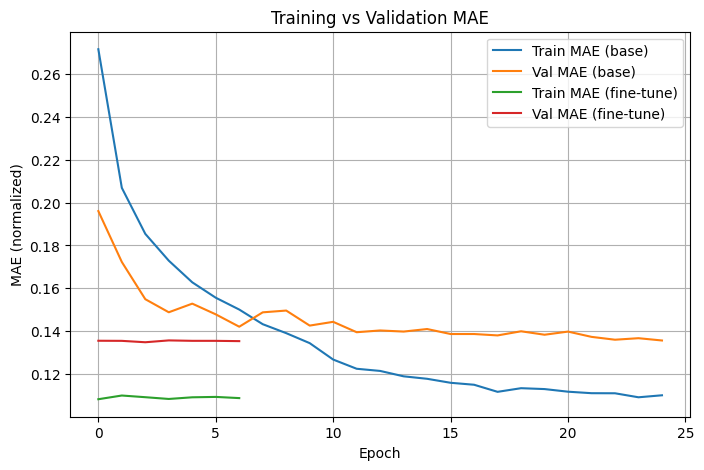

In [13]:
plt.figure(figsize=(8,5))
plt.plot(history.history["mae"], label="Train MAE (base)")
plt.plot(history.history["val_mae"], label="Val MAE (base)")
plt.plot(history_finetune.history["mae"], label="Train MAE (fine-tune)")
plt.plot(history_finetune.history["val_mae"], label="Val MAE (fine-tune)")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()


In [14]:
# --- Evaluate AFTER fine-tuning ---
y_true_ft = []
y_pred_ft = []

for batch in val_ds:
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)
    y_true_ft.extend(labels.numpy().flatten())
    y_pred_ft.extend(preds.flatten())

y_true_ft_months = denormalize_age(np.array(y_true_ft))
y_pred_ft_months = denormalize_age(np.array(y_pred_ft))

ft_mae_months = mean_absolute_error(y_true_ft_months, y_pred_ft_months)
print("FINE-TUNED MODEL Validation MAE (months):", ft_mae_months)


FINE-TUNED MODEL Validation MAE (months): 11.10754334052875


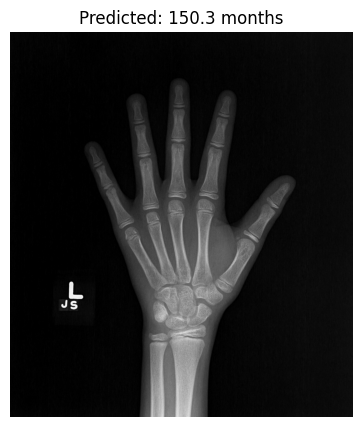

True Age: 150 months
Predicted Age: 150.31 months
Error: 0.31 months


In [15]:
import cv2

def predict_bone_age(image_path, gender_value):
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_preprocessed = preprocess_input(img_resized.astype(np.float32))

    input_tensor = {
        "image_input": np.expand_dims(img_preprocessed, axis=0),
        "gender_input": np.array([[gender_value]], dtype=np.float32)
    }

    pred_norm = model.predict(input_tensor, verbose=0)[0][0]
    pred_months = denormalize_age(pred_norm)

    plt.figure(figsize=(5,5))
    plt.imshow(img_rgb)
    plt.title(f"Predicted: {pred_months:.1f} months")
    plt.axis("off")
    plt.show()

    return pred_months

sample_row = val_df.iloc[0]
sample_path = sample_row["path"]
sample_gender = sample_row["sex"]
true_age = sample_row["boneage"]

predicted_age = predict_bone_age(sample_path, sample_gender)

print(f"True Age: {true_age} months")
print(f"Predicted Age: {predicted_age:.2f} months")
print(f"Error: {abs(true_age - predicted_age):.2f} months")


In [16]:
print("\n==================== RESULTS ====================")
print(f"Base Model MAE:       {base_mae_months:.3f} months")
print(f"Fine-Tuned Model MAE: {ft_mae_months:.3f} months")

improvement = base_mae_months - ft_mae_months
print("Improvement:", improvement, "months" if improvement > 0 else "(got worse)")
print("=================================================\n")



==================== RESULTS ====================
Base Model MAE:       11.175 months
Fine-Tuned Model MAE: 11.108 months
Improvement: 0.0677465939407984 months



In [17]:
def build_efficientnetb0_model():
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    gender_input = layers.Input(shape=(1,), name="gender_input")

    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input
    )

    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    g = layers.Dense(16, activation="relu")(gender_input)
    combined = layers.Concatenate()([x, g])

    z = layers.Dense(256, activation="relu")(combined)
    z = layers.Dropout(0.4)(z)
    z = layers.Dense(64, activation="relu")(z)
    output = layers.Dense(1, activation="linear", dtype="float32")(z)

    model = Model(inputs=[img_input, gender_input], outputs=output)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="mae",
        metrics=["mae"]
    )

    return model

model_b0 = build_efficientnetb0_model()


In [18]:
callbacks_b0 = [
    EarlyStopping(monitor="val_mae", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.3, patience=3, verbose=1),
    ModelCheckpoint("efficientnetb0_base.h5", monitor="val_mae", save_best_only=True)
]

history_b0 = model_b0.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_b0
)

# Evaluate B0 in months
y_true_b0 = []
y_pred_b0 = []

for batch in val_ds:
    inputs, labels = batch
    preds = model_b0.predict(inputs, verbose=0)
    y_true_b0.extend(labels.numpy().flatten())
    y_pred_b0.extend(preds.flatten())

y_true_b0_m = denormalize_age(np.array(y_true_b0))
y_pred_b0_m = denormalize_age(np.array(y_pred_b0))

mae_b0 = mean_absolute_error(y_true_b0_m, y_pred_b0_m)
print("EfficientNetB0 Validation MAE (months):", mae_b0)


Epoch 1/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - loss: 0.3234 - mae: 0.3234

335/335 ━━━━━━━━━━━━━━━━━━━━ 107s 194ms/step - loss: 0.3232 - mae: 0.3232 - val_loss: 0.1896 - val_mae: 0.1896 - learning_rate: 1.0000e-04
Epoch 2/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.2232 - mae: 0.2232

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.2232 - mae: 0.2232 - val_loss: 0.1744 - val_mae: 0.1744 - learning_rate: 1.0000e-04
Epoch 3/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1886 - mae: 0.1886

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1886 - mae: 0.1886 - val_loss: 0.1621 - val_mae: 0.1621 - learning_rate: 1.0000e-04
Epoch 4/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1738 - mae: 0.1738 - val_loss: 0.1693 - val_mae: 0.1693 - learning_rate: 1.0000e-04
Epoch 5/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1636 - mae: 0.1636

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1636 - mae: 0.1636 - val_loss: 0.1560 - val_mae: 0.1560 - learning_rate: 1.0000e-04
Epoch 6/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1551 - mae: 0.1551

...

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1453 - mae: 0.1453 - val_loss: 0.1488 - val_mae: 0.1488 - learning_rate: 1.0000e-04
Epoch 9/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1400 - mae: 0.1400

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1399 - mae: 0.1399 - val_loss: 0.1433 - val_mae: 0.1433 - learning_rate: 1.0000e-04
Epoch 10/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1340 - mae: 0.1340 - val_loss: 0.1498 - val_mae: 0.1498 - learning_rate: 1.0000e-04
Epoch 11/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1302 - mae: 0.1302 - val_loss: 0.1502 - val_mae: 0.1502 - learning_rate: 1.0000e-04
Epoch 12/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1268 - mae: 0.1268
Epoch 12: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1268 - mae: 0.1268 - val_loss: 0.1498 - val_mae: 0.1498 - learning_rate: 1.0000e-04
Epoch 13/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1216 - mae: 0.1216 - val_loss: 0.1464 - val_mae: 0.1464 - learning_rate: 3.0000e-05
Epoch 14/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1173 - mae: 0.1173

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1173 - mae: 0.1173 - val_loss: 0.1427 - val_mae: 0.1427 - learning_rate: 3.0000e-05
Epoch 15/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1163 - mae: 0.1163 - val_loss: 0.1458 - val_mae: 0.1458 - learning_rate: 3.0000e-05
Epoch 16/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1129 - mae: 0.1129

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1129 - mae: 0.1129 - val_loss: 0.1408 - val_mae: 0.1408 - learning_rate: 3.0000e-05
Epoch 17/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1094 - mae: 0.1094 - val_loss: 0.1442 - val_mae: 0.1442 - learning_rate: 3.0000e-05
Epoch 18/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1107 - mae: 0.1107 - val_loss: 0.1410 - val_mae: 0.1410 - learning_rate: 3.0000e-05
Epoch 19/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1091 - mae: 0.1091

335/335 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.1090 - mae: 0.1090 - val_loss: 0.1377 - val_mae: 0.1377 - learning_rate: 3.0000e-05
Epoch 20/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1060 - mae: 0.1060 - val_loss: 0.1413 - val_mae: 0.1413 - learning_rate: 3.0000e-05
EfficientNetB0 Validation MAE (months): 11.342892388505055


In [19]:
def build_efficientnetb4_model():
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    gender_input = layers.Input(shape=(1,), name="gender_input")

    base_model = EfficientNetB4(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input
    )

    for layer in base_model.layers[:-30]:
        layer.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    g = layers.Dense(16, activation="relu")(gender_input)
    combined = layers.Concatenate()([x, g])

    z = layers.Dense(256, activation="relu")(combined)
    z = layers.Dropout(0.4)(z)
    z = layers.Dense(64, activation="relu")(z)
    output = layers.Dense(1, activation="linear", dtype="float32")(z)

    model = Model(inputs=[img_input, gender_input], outputs=output)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="mae",
        metrics=["mae"]
    )

    return model

model_b4 = build_efficientnetb4_model()


71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [20]:
callbacks_b4_base = [
    EarlyStopping(monitor="val_mae", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.3, patience=3, verbose=1),
    ModelCheckpoint("efficientnetb4_base.h5", monitor="val_mae", save_best_only=True)
]

history_b4_base = model_b4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_b4_base
)

# Evaluate B4 base
y_true_b4_base = []
y_pred_b4_base = []

for batch in val_ds:
    inputs, labels = batch
    preds = model_b4.predict(inputs, verbose=0)
    y_true_b4_base.extend(labels.numpy().flatten())
    y_pred_b4_base.extend(preds.flatten())

y_true_b4_base_m = denormalize_age(np.array(y_true_b4_base))
y_pred_b4_base_m = denormalize_age(np.array(y_pred_b4_base))

mae_b4_base = mean_absolute_error(y_true_b4_base_m, y_pred_b4_base_m)
print("EfficientNetB4 BASE Validation MAE (months):", mae_b4_base)


Epoch 1/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - loss: 0.3238 - mae: 0.3238

335/335 ━━━━━━━━━━━━━━━━━━━━ 284s 508ms/step - loss: 0.3237 - mae: 0.3237 - val_loss: 0.2040 - val_mae: 0.2040 - learning_rate: 1.0000e-04
Epoch 2/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.2254 - mae: 0.2254

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - loss: 0.2254 - mae: 0.2254 - val_loss: 0.1840 - val_mae: 0.1840 - learning_rate: 1.0000e-04
Epoch 3/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.2019 - mae: 0.2019

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - loss: 0.2019 - mae: 0.2019 - val_loss: 0.1683 - val_mae: 0.1683 - learning_rate: 1.0000e-04
Epoch 4/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1863 - mae: 0.1863

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - loss: 0.1862 - mae: 0.1862 - val_loss: 0.1630 - val_mae: 0.1630 - learning_rate: 1.0000e-04
Epoch 5/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1746 - mae: 0.1746

...

335/335 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - loss: 0.1424 - mae: 0.1424 - val_loss: 0.1477 - val_mae: 0.1477 - learning_rate: 1.0000e-04
Epoch 11/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1401 - mae: 0.1401

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - loss: 0.1401 - mae: 0.1401 - val_loss: 0.1413 - val_mae: 0.1413 - learning_rate: 1.0000e-04
Epoch 12/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1353 - mae: 0.1353 - val_loss: 0.1528 - val_mae: 0.1528 - learning_rate: 1.0000e-04
Epoch 13/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1336 - mae: 0.1336 - val_loss: 0.1472 - val_mae: 0.1472 - learning_rate: 1.0000e-04
Epoch 14/20
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1287 - mae: 0.1287
Epoch 14: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1287 - mae: 0.1287 - val_loss: 0.1445 - val_mae: 0.1445 - learning_rate: 1.0000e-04
Epoch 15/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1225 - mae: 0.1225

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - loss: 0.1225 - mae: 0.1225 - val_loss: 0.1390 - val_mae: 0.1390 - learning_rate: 3.0000e-05
Epoch 16/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1173 - mae: 0.1173 - val_loss: 0.1417 - val_mae: 0.1417 - learning_rate: 3.0000e-05
Epoch 17/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1141 - mae: 0.1141

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - loss: 0.1141 - mae: 0.1141 - val_loss: 0.1388 - val_mae: 0.1388 - learning_rate: 3.0000e-05
Epoch 18/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1124 - mae: 0.1124 - val_loss: 0.1391 - val_mae: 0.1391 - learning_rate: 3.0000e-05
Epoch 19/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1120 - mae: 0.1120

335/335 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - loss: 0.1120 - mae: 0.1120 - val_loss: 0.1385 - val_mae: 0.1385 - learning_rate: 3.0000e-05
Epoch 20/20
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1092 - mae: 0.1092 - val_loss: 0.1401 - val_mae: 0.1401 - learning_rate: 3.0000e-05
EfficientNetB4 BASE Validation MAE (months): 11.408991804806197


In [21]:
# Unfreeze more top layers for fine-tuning
for layer in model_b4.layers[-40:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

model_b4.compile(
    optimizer=Adam(learning_rate=3e-6),
    loss="mae",
    metrics=["mae"]
)

callbacks_b4_ft = [
    EarlyStopping(monitor="val_mae", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_mae", factor=0.2, patience=2, verbose=1),
    ModelCheckpoint("efficientnetb4_finetuned.h5", monitor="val_mae", save_best_only=True)
]

history_b4_ft = model_b4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_b4_ft
)

# Evaluate B4 fine-tuned
y_true_b4_ft = []
y_pred_b4_ft = []

for batch in val_ds:
    inputs, labels = batch
    preds = model_b4.predict(inputs, verbose=0)
    y_true_b4_ft.extend(labels.numpy().flatten())
    y_pred_b4_ft.extend(preds.flatten())

y_true_b4_ft_m = denormalize_age(np.array(y_true_b4_ft))
y_pred_b4_ft_m = denormalize_age(np.array(y_pred_b4_ft))

mae_b4_ft = mean_absolute_error(y_true_b4_ft_m, y_pred_b4_ft_m)
print("EfficientNetB4 FINE-TUNED Validation MAE (months):", mae_b4_ft)


Epoch 1/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - loss: 0.1076 - mae: 0.1076

335/335 ━━━━━━━━━━━━━━━━━━━━ 203s 364ms/step - loss: 0.1076 - mae: 0.1076 - val_loss: 0.1373 - val_mae: 0.1373 - learning_rate: 3.0000e-06
Epoch 2/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 19s 56ms/step - loss: 0.1053 - mae: 0.1053 - val_loss: 0.1373 - val_mae: 0.1373 - learning_rate: 3.0000e-06
Epoch 3/15
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1064 - mae: 0.1064

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - loss: 0.1064 - mae: 0.1064 - val_loss: 0.1370 - val_mae: 0.1370 - learning_rate: 3.0000e-06
Epoch 4/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - loss: 0.1051 - mae: 0.1051 - val_loss: 0.1371 - val_mae: 0.1371 - learning_rate: 3.0000e-06
Epoch 5/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1032 - mae: 0.1032

335/335 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - loss: 0.1032 - mae: 0.1032 - val_loss: 0.1365 - val_mae: 0.1365 - learning_rate: 3.0000e-06
Epoch 6/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1055 - mae: 0.1055 - val_loss: 0.1370 - val_mae: 0.1370 - learning_rate: 3.0000e-06
Epoch 7/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1050 - mae: 0.1050

335/335 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - loss: 0.1050 - mae: 0.1050 - val_loss: 0.1360 - val_mae: 0.1360 - learning_rate: 3.0000e-06
Epoch 8/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1042 - mae: 0.1042 - val_loss: 0.1366 - val_mae: 0.1366 - learning_rate: 3.0000e-06
Epoch 9/15
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1053 - mae: 0.1053
Epoch 9: ReduceLROnPlateau reducing learning rate to 6.000000212225132e-07.
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1053 - mae: 0.1053 - val_loss: 0.1374 - val_mae: 0.1374 - learning_rate: 3.0000e-06
Epoch 10/15
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1041 - mae: 0.1041 - val_loss: 0.1369 - val_mae: 0.1369 - learning_rate: 6.0000e-07
Epoch 11/15
334/335 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1046 - mae: 0.1046
Epoch 11: ReduceLROnPlateau reducing learning rate to 1.2000000424450263e-07.
335/335 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - loss: 0.1046 - mae: 0.1046 - val_loss: 0.1363 - val_mae: 0.1363 -

In [22]:
print("\n==================== MODEL COMPARISON ====================")
print(f"EfficientNetB0 MAE:              {mae_b0:.3f} months")
print(f"EfficientNetB4 BASE MAE:         {mae_b4_base:.3f} months")
print(f"EfficientNetB4 FINE-TUNED MAE:   {mae_b4_ft:.3f} months")
print("==========================================================\n")



==================== MODEL COMPARISON ====================
EfficientNetB0 MAE:              11.343 months
EfficientNetB4 BASE MAE:         11.409 months
EfficientNetB4 FINE-TUNED MAE:   11.205 months



/tmp/ipykernel_57/2688428069.py:45: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.5),


model.safetensors:   0%|          | 0.00/196M [00:00<?, ?B/s]

/tmp/ipykernel_57/2688428069.py:156: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
  0%|          | 0/2838 [00:00<?, ?it/s]/tmp/ipykernel_57/2688428069.py:173: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/10 Loss: 25.4129: 100%|██████████| 2838/2838 [06:56<00:00,  6.82it/s]


Epoch 1 | Train Loss: 15.7356 | Val MAE: 30.0485


Epoch 2/10 Loss: 6.8477: 100%|██████████| 2838/2838 [06:43<00:00,  7.03it/s] 


...

Epoch 8 | Train Loss: 6.3141 | Val MAE: 7.9866


Epoch 9/10 Loss: 24.6223: 100%|██████████| 2838/2838 [06:44<00:00,  7.02it/s]


Epoch 9 | Train Loss: 6.2211 | Val MAE: 10.3735


Epoch 10/10 Loss: 11.2027: 100%|██████████| 2838/2838 [06:44<00:00,  7.01it/s]


Epoch 10 | Train Loss: 6.0569 | Val MAE: 7.5857


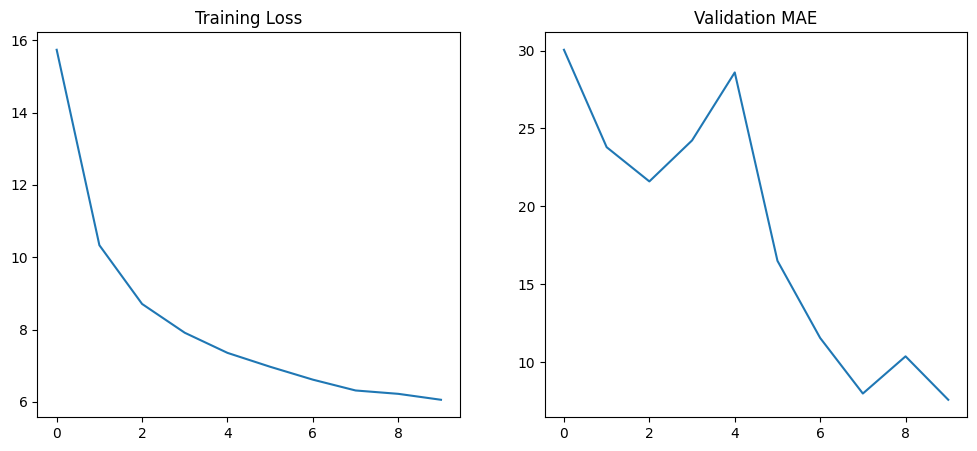

In [1]:
# ===========================
# RSNA BONE AGE – FULL PIPELINE (T4 SAFE)
# SEResNeXt101 + Hybrid Loss + AMP + 384px images
# ===========================

import os
import cv2
import torch
import numpy as np
import pandas as pd
import albumentations as A
import matplotlib.pyplot as plt
import timm
import torch.nn as nn

from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# ---------------------------
# PATHS & DATAFRAME
# ---------------------------
base_dir = "/kaggle/input/datasets/kmader/rsna-bone-age"

train_csv_path = os.path.join(base_dir, "boneage-training-dataset.csv")
train_img_dir  = os.path.join(base_dir, "boneage-training-dataset", "boneage-training-dataset")

df = pd.read_csv(train_csv_path)
df["male"] = df["male"].astype(int)

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

# ---------------------------
# TRANSFORMS (384px to avoid OOM)
# ---------------------------
train_tfms = A.Compose([
    A.RandomResizedCrop(size=(384, 384), scale=(0.8, 1.0), ratio=(0.75, 1.33)),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.CLAHE(p=0.3),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.5),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5)),
    ToTensorV2()
])

val_tfms = A.Compose([
    A.Resize(height=384, width=384),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5)),
    ToTensorV2()
])

# ---------------------------
# DATASET
# ---------------------------
class BoneAgeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = os.path.join(self.img_dir, f"{row['id']}.png")
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        age = torch.tensor(row["boneage"], dtype=torch.float32)
        gender = torch.tensor(row["male"], dtype=torch.long)

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, gender, age

# ---------------------------
# DATALOADERS (batch_size=4)
# ---------------------------
train_loader = DataLoader(
    BoneAgeDataset(train_df, train_img_dir, transform=train_tfms),
    batch_size=4, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    BoneAgeDataset(val_df, train_img_dir, transform=val_tfms),
    batch_size=4, shuffle=False, num_workers=2
)

# ---------------------------
# MODEL
# ---------------------------
class BoneAgeModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = timm.create_model(
            "seresnext101_32x4d",
            pretrained=True,
            num_classes=0
        )

        self.gender_embed = nn.Embedding(2, 16)

        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))

        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        age = (prob * months).sum(dim=1)

        return logits, age

# ---------------------------
# LOSS & EVAL
# ---------------------------
def hybrid_loss(logits, pred_age, true_age):
    ce = nn.CrossEntropyLoss()(logits, true_age.long())
    mae = torch.abs(pred_age - true_age).mean()
    return ce + 0.5 * mae

def evaluate(model, val_loader, device):
    model.eval()
    maes = []
    with torch.no_grad():
        for img, gender, age in val_loader:
            img, gender, age = img.to(device), gender.to(device), age.to(device)
            _, pred_age = model(img, gender)
            maes.append(torch.abs(pred_age - age).mean().item())
    return np.mean(maes)

# ---------------------------
# TRAINING (AMP + OOM SAFE)
# ---------------------------
device = "cuda"
model = BoneAgeModel().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

num_epochs = 10
train_losses, val_maes = [], []
best_mae = float("inf")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader)
    for img, gender, age in pbar:
        img, gender, age = img.to(device), gender.to(device), age.to(device)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            logits, pred_age = model(img, gender)
            loss = hybrid_loss(logits, pred_age, age)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        pbar.set_description(f"Epoch {epoch+1}/{num_epochs} Loss: {loss.item():.4f}")

    torch.cuda.empty_cache()
    scheduler.step()

    train_loss = running_loss / len(train_loader)
    val_mae = evaluate(model, val_loader, device)

    train_losses.append(train_loss)
    val_maes.append(val_mae)

    if val_mae < best_mae:
        best_mae = val_mae
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Val MAE: {val_mae:.4f}")

# ---------------------------
# PLOT LOSS & MAE
# ---------------------------
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(train_losses); plt.title("Training Loss")
plt.subplot(1,2,2)
plt.plot(val_maes); plt.title("Validation MAE")
plt.show()



In [5]:
# ===========================
# COLLECT ALL PREDICTIONS
# ===========================
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

all_preds = []
all_actuals = []

with torch.no_grad():
    for img, gender, age in val_loader:
        img, gender = img.to(device), gender.to(device)
        with torch.amp.autocast('cuda'):
            _, pred_age = model(img, gender)

        all_preds.extend(pred_age.cpu().numpy())
        all_actuals.extend(age.numpy())

all_preds = np.array(all_preds)
all_actuals = np.array(all_actuals)

mae_score = np.mean(np.abs(all_preds - all_actuals))
print("Validation MAE:", mae_score)


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ccd84b8f4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ccd84b8f4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Validation MAE: 7.9557204


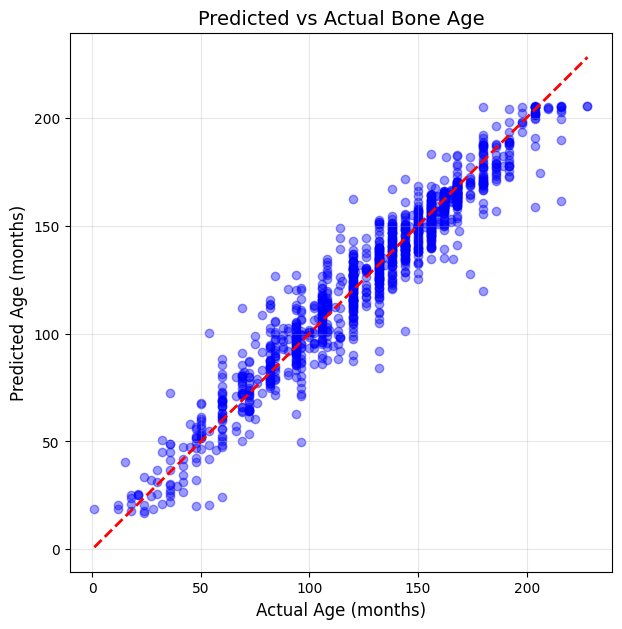

In [6]:
# ===========================
# SCATTER PLOT: Predicted vs Actual
# ===========================
plt.figure(figsize=(7,7))
plt.scatter(all_actuals, all_preds, alpha=0.4, color='blue')

# Diagonal reference line
min_age = min(all_actuals.min(), all_preds.min())
max_age = max(all_actuals.max(), all_preds.max())
plt.plot([min_age, max_age], [min_age, max_age], 'r--', linewidth=2)

plt.xlabel("Actual Age (months)", fontsize=12)
plt.ylabel("Predicted Age (months)", fontsize=12)
plt.title("Predicted vs Actual Bone Age", fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()


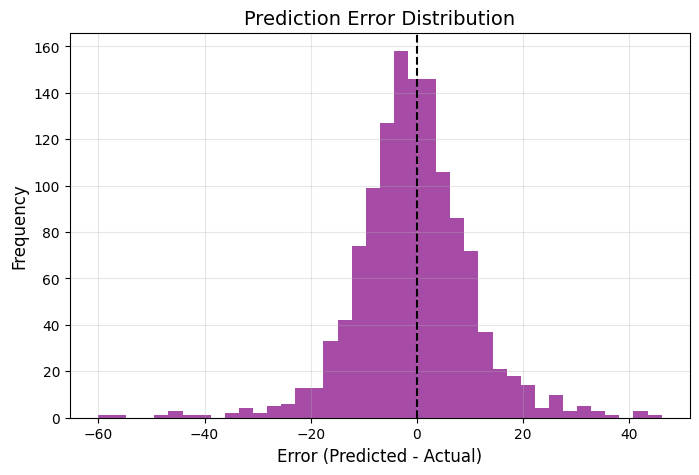

In [7]:
# ===========================
# HISTOGRAM: Prediction Error
# ===========================
errors = all_preds - all_actuals

plt.figure(figsize=(8,5))
plt.hist(errors, bins=40, color='purple', alpha=0.7)
plt.axvline(0, color='black', linestyle='--')

plt.title("Prediction Error Distribution", fontsize=14)
plt.xlabel("Error (Predicted - Actual)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()


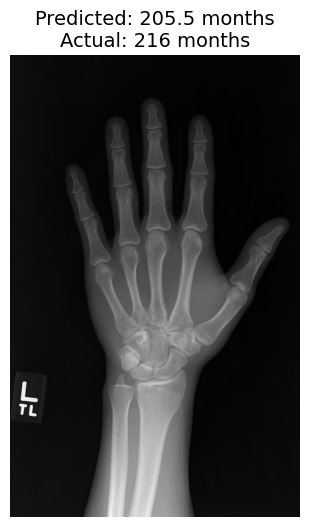

In [8]:
# ===========================
# SAMPLE PREDICTION VISUALIZATION
# ===========================
sample = val_df.sample(1).iloc[0]
img_path = os.path.join(train_img_dir, f"{sample['id']}.png")

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

tfm = val_tfms(image=img_rgb)["image"].unsqueeze(0).to(device)
gender_tensor = torch.tensor([sample["male"]], dtype=torch.long).to(device)

with torch.no_grad():
    with torch.amp.autocast('cuda'):
        _, pred_age = model(tfm, gender_tensor)

pred_age_val = pred_age.item()
actual_age_val = sample["boneage"]

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.axis("off")
plt.title(
    f"Predicted: {pred_age_val:.1f} months\nActual: {actual_age_val} months",
    fontsize=14
)
plt.show()


In [9]:
print("====================================")
print("        MODEL PERFORMANCE")
print("====================================")

# Only print if val_maes exists
if 'val_maes' in globals() and len(val_maes) > 0:
    print(f"Best Validation MAE (during training): {min(val_maes):.3f}")
else:
    print("Best Validation MAE (during training): N/A (training not run)")

print(f"Final Validation MAE (full eval)     : {mae_score:.3f}")
print("------------------------------------")
print(f"Mean Error (Pred-Actual)             : {errors.mean():.3f}")
print(f"Std Dev of Error                     : {errors.std():.3f}")
print("====================================")


        MODEL PERFORMANCE
Best Validation MAE (during training): 7.586
Final Validation MAE (full eval)     : 7.956
------------------------------------
Mean Error (Pred-Actual)             : -0.688
Std Dev of Error                     : 10.899


model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

[EffB4] Epoch 1/25 | Loss: 14.021 | Val MAE: 11.884 | Best: 11.884
[EffB4] Epoch 2/25 | Loss: 10.088 | Val MAE: 9.967 | Best: 9.967
[EffB4] Epoch 3/25 | Loss: 9.234 | Val MAE: 9.660 | Best: 9.660
[EffB4] Epoch 4/25 | Loss: 10.185 | Val MAE: 8.693 | Best: 8.693
[EffB4] Epoch 5/25 | Loss: 9.378 | Val MAE: 9.327 | Best: 8.693
[EffB4] Epoch 6/25 | Loss: 8.994 | Val MAE: 7.707 | Best: 7.707
[EffB4] Epoch 7/25 | Loss: 8.600 | Val MAE: 8.171 | Best: 7.707
[EffB4] Epoch 8/25 | Loss: 8.361 | Val MAE: 7.652 | Best: 7.652
[EffB4] Epoch 9/25 | Loss: 8.027 | Val MAE: 7.349 | Best: 7.349
[EffB4] Epoch 10/25 | Loss: 7.834 | Val MAE: 7.323 | Best: 7.323
[EffB4] Epoch 11/25 | Loss: 7.576 | Val MAE: 7.374 | Best: 7.323
[EffB4] Epoch 12/25 | Loss: 7.424 | Val MAE: 7.220 | Best: 7.220
[EffB4] Epoch 13/25 | Loss: 7.288 | Val MAE: 7.216 | Best: 7.216
[EffB4] Epoch 14/25 | Loss: 7.113 | Val MAE: 7.189 | Best: 7.189
[EffB4] Epoch 15/25 | Loss: 7.065 | Val MAE: 7.078 | Best: 7.078
[EffB4] Epoch 16/25 | Loss: 7

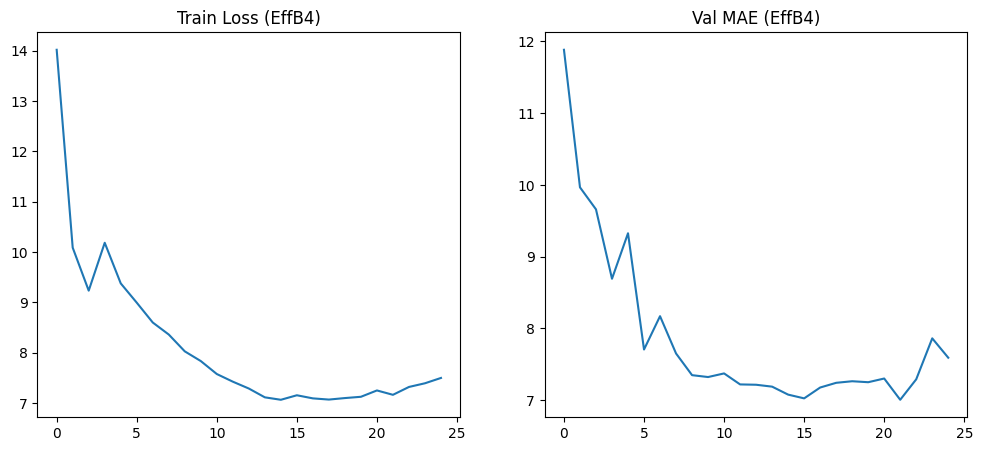

In [10]:
# ============================================================
# RSNA BONE AGE – EfficientNet-B4, 384px (FAST + ACCURATE)
# Fully corrected for Albumentations v1.4+
# ============================================================

import os, cv2, torch, timm
import numpy as np, pandas as pd, albumentations as A
import matplotlib.pyplot as plt
import torch.nn as nn

from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# ---------------------------
# PATHS & DATAFRAME
# ---------------------------
base_dir = "/kaggle/input/datasets/kmader/rsna-bone-age"
csv_path = os.path.join(base_dir, "boneage-training-dataset.csv")
img_dir  = os.path.join(base_dir, "boneage-training-dataset", "boneage-training-dataset")

df = pd.read_csv(csv_path)
df["male"] = df["male"].astype(int)

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

# ---------------------------
# TRANSFORMS (384px, ImageNet norm)
# ---------------------------
IMG_SIZE = 384
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std  = (0.229, 0.224, 0.225)

train_tfms = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.85, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(0.02, 0.02),
             rotate=(-10, 10), p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.CLAHE(p=0.4),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ToTensorV2()
])

val_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ToTensorV2()
])

# ---------------------------
# DATASET
# ---------------------------
class BoneAgeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        age = torch.tensor(row["boneage"], dtype=torch.float32)
        gender = torch.tensor(row["male"], dtype=torch.long)

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, gender, age

train_loader = DataLoader(
    BoneAgeDataset(train_df, img_dir, train_tfms),
    batch_size=8, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    BoneAgeDataset(val_df, img_dir, val_tfms),
    batch_size=8, shuffle=False, num_workers=2
)

# ---------------------------
# MODEL (EfficientNet-B4)
# ---------------------------
class BoneAgeEffNetB4(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            "efficientnet_b4",
            pretrained=True,
            num_classes=0
        )
        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))
        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        age = (prob * months).sum(dim=1)
        return logits, age

device = "cuda"
model = BoneAgeEffNetB4().to(device)

# ---------------------------
# LOSS (warmup) & OPTIM
# ---------------------------
def hybrid_loss(logits, pred_age, true_age, epoch, warmup_epochs=3):
    target_cls = true_age.clamp(0, 239).long()
    mae = torch.abs(pred_age - true_age).mean()
    if epoch < warmup_epochs:
        return mae
    ce = nn.CrossEntropyLoss()(logits, target_cls)
    return 0.5 * ce + 1.0 * mae

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

# ---------------------------
# EVAL
# ---------------------------
def evaluate(model, loader, device):
    model.eval()
    maes = []
    with torch.no_grad():
        for img, gender, age in loader:
            img, gender, age = img.to(device), gender.to(device), age.to(device)
            with torch.amp.autocast('cuda'):
                _, pred_age = model(img, gender)
            maes.append(torch.abs(pred_age - age).mean().item())
    return np.mean(maes)

# ---------------------------
# TRAIN
# ---------------------------
num_epochs = 25
train_losses, val_maes = [], []
best_mae = float("inf")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for img, gender, age in train_loader:
        img, gender, age = img.to(device), gender.to(device), age.to(device)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            logits, pred_age = model(img, gender)
            loss = hybrid_loss(logits, pred_age, age, epoch)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()

    scheduler.step()
    train_loss = running_loss / len(train_loader)
    val_mae = evaluate(model, val_loader, device)
    train_losses.append(train_loss)
    val_maes.append(val_mae)

    if val_mae < best_mae:
        best_mae = val_mae
        torch.save(model.state_dict(), "best_effb4_384_25.pth")

    print(f"[EffB4] Epoch {epoch+1}/{num_epochs} | Loss: {train_loss:.3f} | Val MAE: {val_mae:.3f} | Best: {best_mae:.3f}")

# ---------------------------
# PLOTS
# ---------------------------
plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.plot(train_losses); plt.title("Train Loss (EffB4)")
plt.subplot(1,2,2); plt.plot(val_maes); plt.title("Val MAE (EffB4)")
plt.show()


In [11]:
# ===========================
# COLLECT ALL PREDICTIONS
# ===========================
model.load_state_dict(torch.load("best_effb4_384_25.pth"))
model.eval()

all_preds = []
all_actuals = []

with torch.no_grad():
    for img, gender, age in val_loader:
        img, gender = img.to(device), gender.to(device)
        with torch.amp.autocast('cuda'):
            _, pred_age = model(img, gender)

        all_preds.extend(pred_age.cpu().numpy())
        all_actuals.extend(age.numpy())

all_preds = np.array(all_preds)
all_actuals = np.array(all_actuals)

mae_score = np.mean(np.abs(all_preds - all_actuals))
print("Validation MAE:", mae_score)


Validation MAE: 7.0028415


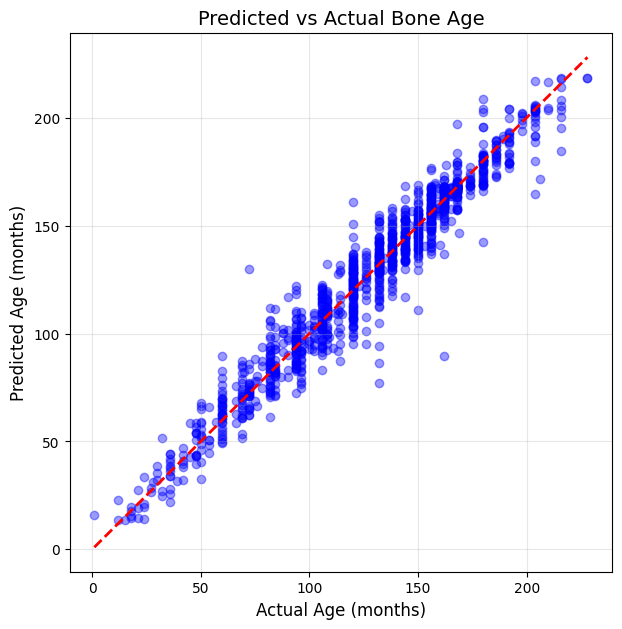

In [12]:
# ===========================
# SCATTER PLOT: Predicted vs Actual
# ===========================
plt.figure(figsize=(7,7))
plt.scatter(all_actuals, all_preds, alpha=0.4, color='blue')

# Diagonal reference line
min_age = min(all_actuals.min(), all_preds.min())
max_age = max(all_actuals.max(), all_preds.max())
plt.plot([min_age, max_age], [min_age, max_age], 'r--', linewidth=2)

plt.xlabel("Actual Age (months)", fontsize=12)
plt.ylabel("Predicted Age (months)", fontsize=12)
plt.title("Predicted vs Actual Bone Age", fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()


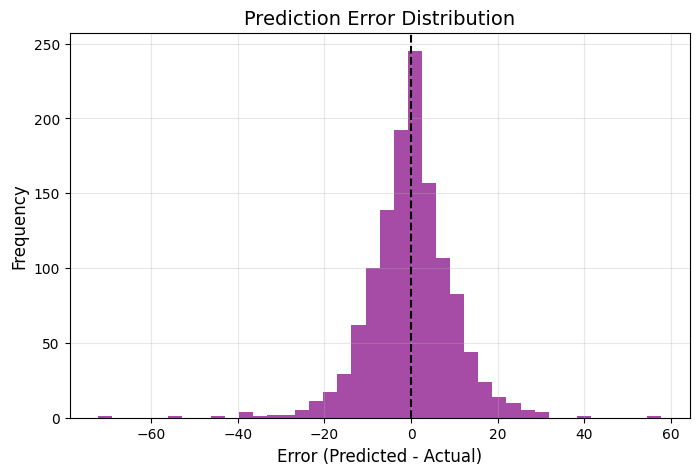

In [13]:
# ===========================
# HISTOGRAM: Prediction Error
# ===========================
errors = all_preds - all_actuals

plt.figure(figsize=(8,5))
plt.hist(errors, bins=40, color='purple', alpha=0.7)
plt.axvline(0, color='black', linestyle='--')

plt.title("Prediction Error Distribution", fontsize=14)
plt.xlabel("Error (Predicted - Actual)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()


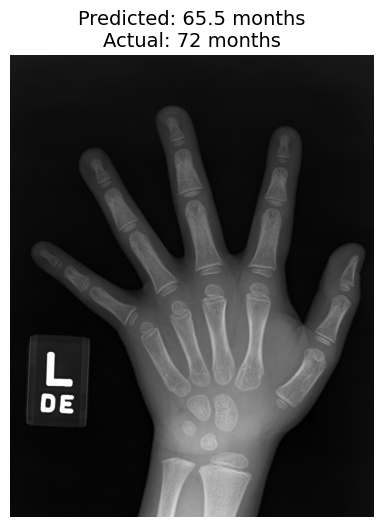

In [14]:
# ===========================
# SAMPLE PREDICTION VISUALIZATION
# ===========================
sample = val_df.sample(1).iloc[0]
img_path = os.path.join(train_img_dir, f"{sample['id']}.png")

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

tfm = val_tfms(image=img_rgb)["image"].unsqueeze(0).to(device)
gender_tensor = torch.tensor([sample["male"]], dtype=torch.long).to(device)

with torch.no_grad():
    with torch.amp.autocast('cuda'):
        _, pred_age = model(tfm, gender_tensor)

pred_age_val = pred_age.item()
actual_age_val = sample["boneage"]

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.axis("off")
plt.title(
    f"Predicted: {pred_age_val:.1f} months\nActual: {actual_age_val} months",
    fontsize=14
)
plt.show()


In [15]:
print("====================================")
print("        MODEL PERFORMANCE")
print("====================================")

# Only print if val_maes exists
if 'val_maes' in globals() and len(val_maes) > 0:
    print(f"Best Validation MAE (during training): {min(val_maes):.3f}")
else:
    print("Best Validation MAE (during training): N/A (training not run)")

print(f"Final Validation MAE (full eval)     : {mae_score:.3f}")
print("------------------------------------")
print(f"Mean Error (Pred-Actual)             : {errors.mean():.3f}")
print(f"Std Dev of Error                     : {errors.std():.3f}")
print("====================================")


        MODEL PERFORMANCE
Best Validation MAE (during training): 7.006
Final Validation MAE (full eval)     : 7.003
------------------------------------
Mean Error (Pred-Actual)             : -0.046
Std Dev of Error                     : 9.796


model.safetensors:   0%|          | 0.00/96.5M [00:00<?, ?B/s]

[EffNetV2-RW-S] Epoch 1/30 | Loss: 20.394 | Val MAE: 14.665
[EffNetV2-RW-S] Epoch 2/30 | Loss: 13.004 | Val MAE: 13.255
[EffNetV2-RW-S] Epoch 3/30 | Loss: 11.085 | Val MAE: 10.740
[EffNetV2-RW-S] Epoch 4/30 | Loss: 11.138 | Val MAE: 16.186
[EffNetV2-RW-S] Epoch 5/30 | Loss: 9.949 | Val MAE: 11.063
[EffNetV2-RW-S] Epoch 6/30 | Loss: 9.433 | Val MAE: 16.329
[EffNetV2-RW-S] Epoch 7/30 | Loss: 8.962 | Val MAE: 7.666
[EffNetV2-RW-S] Epoch 8/30 | Loss: 8.665 | Val MAE: 9.317
[EffNetV2-RW-S] Epoch 9/30 | Loss: 8.339 | Val MAE: 8.235
[EffNetV2-RW-S] Epoch 10/30 | Loss: 8.116 | Val MAE: 7.874
[EffNetV2-RW-S] Epoch 11/30 | Loss: 7.791 | Val MAE: 6.964
[EffNetV2-RW-S] Epoch 12/30 | Loss: 7.549 | Val MAE: 7.642
[EffNetV2-RW-S] Epoch 13/30 | Loss: 7.398 | Val MAE: 6.983
[EffNetV2-RW-S] Epoch 14/30 | Loss: 7.219 | Val MAE: 6.841
[EffNetV2-RW-S] Epoch 15/30 | Loss: 7.201 | Val MAE: 6.824
[EffNetV2-RW-S] Epoch 16/30 | Loss: 7.131 | Val MAE: 6.844
[EffNetV2-RW-S] Epoch 17/30 | Loss: 7.273 | Val MAE: 6.

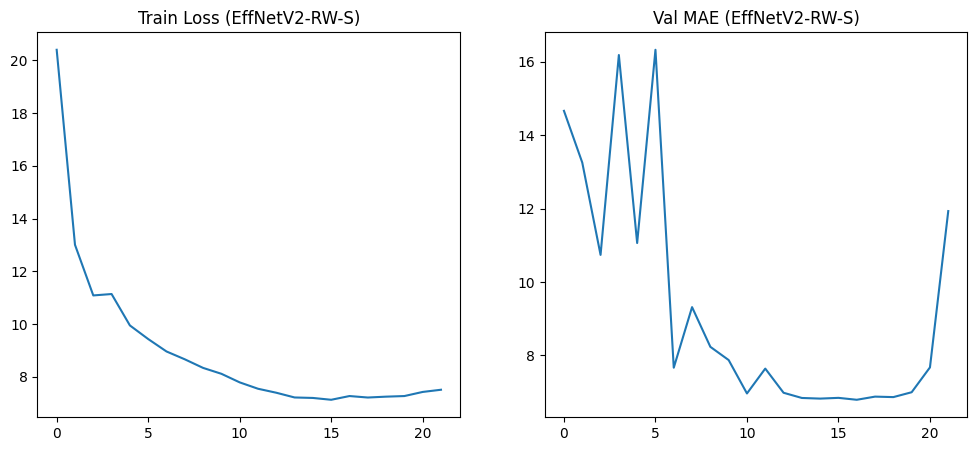

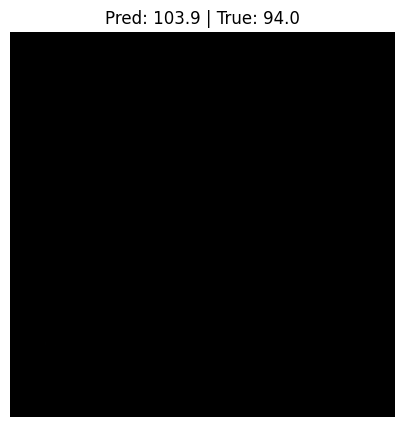

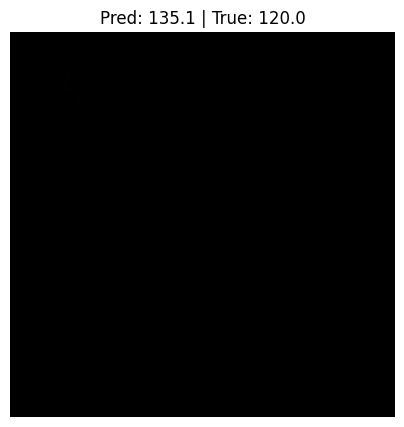

In [16]:
# ============================================================
# RSNA BONE AGE – EfficientNet-V2-RW-S + EARLY STOPPING
# ============================================================

import os, cv2, torch, timm
import numpy as np, pandas as pd, albumentations as A
import matplotlib.pyplot as plt
import torch.nn as nn

from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# ---------------------------
# PATHS
# ---------------------------
base_dir = "/kaggle/input/datasets/kmader/rsna-bone-age"
csv_path = os.path.join(base_dir, "boneage-training-dataset.csv")
img_dir  = os.path.join(base_dir, "boneage-training-dataset", "boneage-training-dataset")

df = pd.read_csv(csv_path)
df["male"] = df["male"].astype(int)

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

# ---------------------------
# TRANSFORMS
# ---------------------------
IMG_SIZE = 384
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std  = (0.229, 0.224, 0.225)

train_tfms = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.85, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(0.02, 0.02),
             rotate=(-10, 10), p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.CLAHE(p=0.4),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ToTensorV2()
])

val_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ToTensorV2()
])

# ---------------------------
# DATASET
# ---------------------------
class BoneAgeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        age = torch.tensor(row["boneage"], dtype=torch.float32)
        gender = torch.tensor(row["male"], dtype=torch.long)

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, gender, age

train_loader = DataLoader(
    BoneAgeDataset(train_df, img_dir, train_tfms),
    batch_size=8, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    BoneAgeDataset(val_df, img_dir, val_tfms),
    batch_size=8, shuffle=False, num_workers=2
)

# ---------------------------
# MODEL: EfficientNet-V2-RW-S
# ---------------------------
class BoneAgeEffNetV2RW(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            "efficientnetv2_rw_s",
            pretrained=True,   # THIS WORKS ON KAGGLE
            num_classes=0
        )
        self.gender_embed = nn.Embedding(2, 16)

        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))

        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        age = (prob * months).sum(dim=1)

        return logits, age

device = "cuda"
model = BoneAgeEffNetV2RW().to(device)

# ---------------------------
# LOSS + OPTIMIZER
# ---------------------------
def hybrid_loss(logits, pred_age, true_age, epoch, warmup_epochs=3):
    target_cls = true_age.clamp(0, 239).long()
    mae = torch.abs(pred_age - true_age).mean()
    if epoch < warmup_epochs:
        return mae
    ce = nn.CrossEntropyLoss()(logits, target_cls)
    return 0.5 * ce + mae

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

# ---------------------------
# EARLY STOPPING
# ---------------------------
class EarlyStopping:
    def __init__(self, patience=5):
        self.patience = patience
        self.counter = 0
        self.best_mae = float("inf")
        self.early_stop = False

    def step(self, mae):
        if mae < self.best_mae:
            self.best_mae = mae
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

early_stopper = EarlyStopping(patience=5)

# ---------------------------
# EVALUATION
# ---------------------------
def evaluate(model, loader):
    model.eval()
    maes = []
    with torch.no_grad():
        for img, gender, age in loader:
            img, gender, age = img.to(device), gender.to(device), age.to(device)
            with torch.amp.autocast('cuda'):
                _, pred_age = model(img, gender)
            maes.append(torch.abs(pred_age - age).mean().item())
    return np.mean(maes)

# ---------------------------
# TRAINING LOOP
# ---------------------------
num_epochs = 30
train_losses, val_maes = [], []
best_mae = float("inf")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for img, gender, age in train_loader:
        img, gender, age = img.to(device), gender.to(device), age.to(device)
        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            logits, pred_age = model(img, gender)
            loss = hybrid_loss(logits, pred_age, age, epoch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()

    scheduler.step()
    train_loss = running_loss / len(train_loader)
    val_mae = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_maes.append(val_mae)

    print(f"[EffNetV2-RW-S] Epoch {epoch+1}/{num_epochs} | Loss: {train_loss:.3f} | Val MAE: {val_mae:.3f}")

    if val_mae < best_mae:
        best_mae = val_mae
        torch.save(model.state_dict(), "best_effnetv2_rw_s.pth")

    early_stopper.step(val_mae)
    if early_stopper.early_stop:
        print("Early stopping triggered!")
        break

print("Training complete. Best MAE:", best_mae)

# ---------------------------
# PLOTS
# ---------------------------
plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.plot(train_losses); plt.title("Train Loss (EffNetV2-RW-S)")
plt.subplot(1,2,2); plt.plot(val_maes); plt.title("Val MAE (EffNetV2-RW-S)")
plt.show()



In [24]:
# ===========================
# COLLECT ALL PREDICTIONS
# ===========================
model.load_state_dict(torch.load("best_effnetv2_rw_s.pth"))
model.eval()

all_preds = []
all_actuals = []

with torch.no_grad():
    for img, gender, age in val_loader:
        img, gender = img.to(device), gender.to(device)
        with torch.amp.autocast('cuda'):
            _, pred_age = model(img, gender)

        all_preds.extend(pred_age.cpu().numpy())
        all_actuals.extend(age.numpy())

all_preds = np.array(all_preds)
all_actuals = np.array(all_actuals)

mae_score = np.mean(np.abs(all_preds - all_actuals))
print("Validation MAE:", mae_score)


Validation MAE: 6.7880116


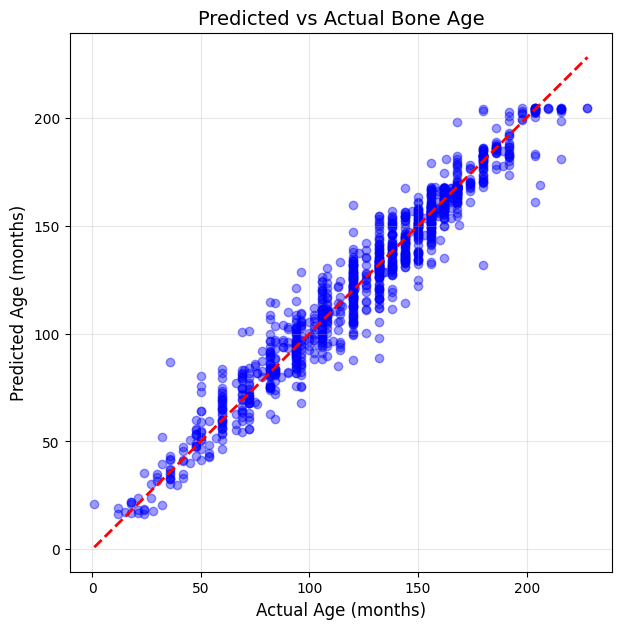

In [25]:
# ===========================
# SCATTER PLOT: Predicted vs Actual
# ===========================
plt.figure(figsize=(7,7))
plt.scatter(all_actuals, all_preds, alpha=0.4, color='blue')

# Diagonal reference line
min_age = min(all_actuals.min(), all_preds.min())
max_age = max(all_actuals.max(), all_preds.max())
plt.plot([min_age, max_age], [min_age, max_age], 'r--', linewidth=2)

plt.xlabel("Actual Age (months)", fontsize=12)
plt.ylabel("Predicted Age (months)", fontsize=12)
plt.title("Predicted vs Actual Bone Age", fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()


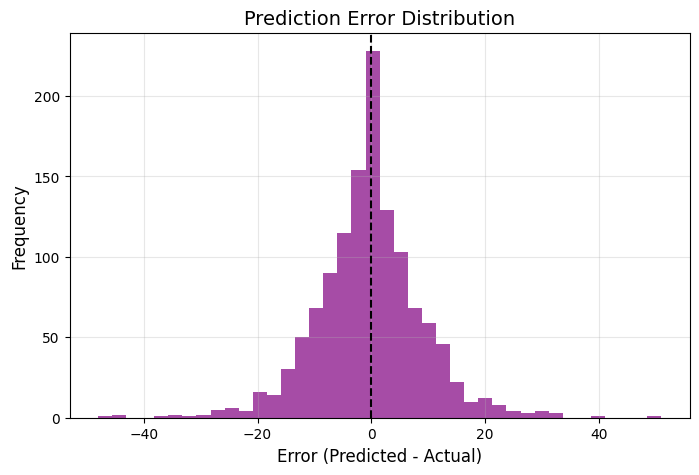

In [26]:
# ===========================
# HISTOGRAM: Prediction Error
# ===========================
errors = all_preds - all_actuals

plt.figure(figsize=(8,5))
plt.hist(errors, bins=40, color='purple', alpha=0.7)
plt.axvline(0, color='black', linestyle='--')

plt.title("Prediction Error Distribution", fontsize=14)
plt.xlabel("Error (Predicted - Actual)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()


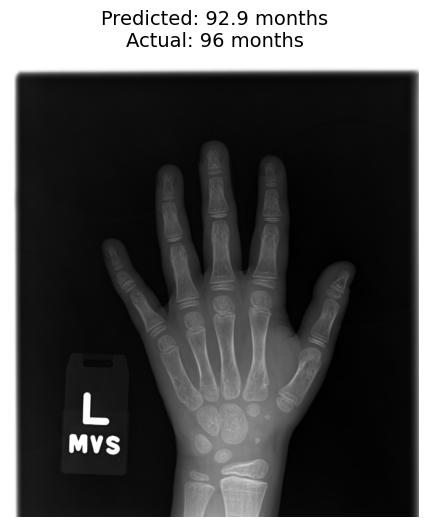

In [33]:
# ===========================
# SAMPLE PREDICTION VISUALIZATION
# ===========================
sample = val_df.sample(1).iloc[0]
img_path = os.path.join(train_img_dir, f"{sample['id']}.png")

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

tfm = val_tfms(image=img_rgb)["image"].unsqueeze(0).to(device)
gender_tensor = torch.tensor([sample["male"]], dtype=torch.long).to(device)

with torch.no_grad():
    with torch.amp.autocast('cuda'):
        _, pred_age = model(tfm, gender_tensor)

pred_age_val = pred_age.item()
actual_age_val = sample["boneage"]

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.axis("off")
plt.title(
    f"Predicted: {pred_age_val:.1f} months\nActual: {actual_age_val} months",
    fontsize=14
)
plt.show()


In [28]:
print("====================================")
print("        MODEL PERFORMANCE")
print("====================================")

# Only print if val_maes exists
if 'val_maes' in globals() and len(val_maes) > 0:
    print(f"Best Validation MAE (during training): {min(val_maes):.3f}")
else:
    print("Best Validation MAE (during training): N/A (training not run)")

print(f"Final Validation MAE (full eval)     : {mae_score:.3f}")
print("------------------------------------")
print(f"Mean Error (Pred-Actual)             : {errors.mean():.3f}")
print(f"Std Dev of Error                     : {errors.std():.3f}")
print("====================================")


        MODEL PERFORMANCE
Best Validation MAE (during training): 6.792
Final Validation MAE (full eval)     : 6.788
------------------------------------
Mean Error (Pred-Actual)             : -0.385
Std Dev of Error                     : 9.469


In [36]:
# ============================================================
# RSNA BONE AGE – FINAL SOTA ENSEMBLE (WORKING VERSION)
# EffB4 + EffNetV2-RW-S + SEResNeXt101 (240-class ordinal)
# ============================================================

import os, cv2, torch, timm
import numpy as np, pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ---------------------------
# PATHS
# ---------------------------
base_dir       = "/kaggle/input/datasets/kmader/rsna-bone-age"
test_csv_path  = os.path.join(base_dir, "boneage-test-dataset.csv")
test_img_dir   = os.path.join(base_dir, "boneage-test-dataset", "boneage-test-dataset")

effb4_ckpt_path = "/kaggle/working/best_effb4_384_25.pth"
effv2_ckpt_path = "/kaggle/working/best_effnetv2_rw_s.pth"
seres_ckpt_path = "/kaggle/working/best_model.pth"

# ---------------------------
# LOAD TEST CSV
# ---------------------------
test_df = pd.read_csv(test_csv_path)

# Convert Case ID → id
test_df["id"] = test_df["Case ID"].astype(str)

# Convert Sex → gender (0/1)
test_df["gender"] = (test_df["Sex"] == "M").astype(int)

print(test_df.head())

# ---------------------------
# TRANSFORMS
# ---------------------------
IMG_SIZE = 384
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std  = (0.229, 0.224, 0.225)

test_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ToTensorV2()
])

# ---------------------------
# DATASET
# ---------------------------
class BoneAgeTestDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        gender = torch.tensor(row["gender"], dtype=torch.long)

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, gender, row["id"]

test_dataset = BoneAgeTestDataset(test_df, test_img_dir, test_tfms)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=2)

# ---------------------------
# MODELS (240-class ordinal)
# ---------------------------

class EffB4Ordinal(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model("tf_efficientnet_b4_ns", pretrained=False, num_classes=0)
        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))
        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        return (prob * months).sum(dim=1)

class EffNetV2RW(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model("efficientnetv2_rw_s", pretrained=False, num_classes=0)
        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))
        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        return (prob * months).sum(dim=1)

class SEResNeXt101(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model("seresnext101_32x4d", pretrained=False, num_classes=0)
        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))
        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        return (prob * months).sum(dim=1)

# ---------------------------
# LOAD CHECKPOINTS
# ---------------------------
effb4 = EffB4Ordinal().to(device)
effb4.load_state_dict(torch.load(effb4_ckpt_path, map_location=device))
effb4.eval()

effv2 = EffNetV2RW().to(device)
effv2.load_state_dict(torch.load(effv2_ckpt_path, map_location=device))
effv2.eval()

seres = SEResNeXt101().to(device)
seres.load_state_dict(torch.load(seres_ckpt_path, map_location=device))
seres.eval()

# ---------------------------
# ENSEMBLE PREDICTION
# ---------------------------
def predict_ensemble(models, loader):
    effb4, effv2, seres = models
    ids_all, preds_all = [], []

    with torch.no_grad():
        for img, gender, ids in loader:
            img = img.to(device)
            gender = gender.to(device)

            age_b4  = effb4(img, gender)
            age_v2  = effv2(img, gender)
            age_ser = seres(img, gender)

            age_ens = 0.35 * age_b4 + 0.35 * age_v2 + 0.30 * age_ser

            ids_all.extend(ids)
            preds_all.extend(age_ens.cpu().numpy())

    return ids_all, np.array(preds_all)

# ---------------------------
# RUN ENSEMBLE
# ---------------------------
ids, preds = predict_ensemble((effb4, effv2, seres), test_loader)

submission = pd.DataFrame({"id": ids, "boneage": preds})
submission = submission.sort_values("id")
submission.to_csv("submission_ensemble_sota.csv", index=False)

print(submission.head())
print("Saved:", "submission_ensemble_sota.csv")


Using device: cuda
   Case ID Sex    id  gender
0     4360   M  4360       1
1     4361   M  4361       1
2     4362   M  4362       1
3     4363   M  4363       1
4     4364   M  4364       1


/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name tf_efficientnet_b4_ns to current tf_efficientnet_b4.ns_jft_in1k.
  model = create_fn(


     id     boneage
0  4360   96.729225
1  4361  131.087112
2  4362   64.406250
3  4363   90.409576
4  4364   88.332008
Saved: submission_ensemble_sota.csv


In [40]:
# ============================================================
# RSNA BONE AGE – FULL SOTA PIPELINE (TRAIN/VAL + TEST)
# EffB4 + EffNetV2-RW-S + SEResNeXt101 (240-class ordinal)
# ============================================================

import os, cv2, torch, timm
import numpy as np, pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 1. LOAD TRAINING CSV
# ============================================================

train_csv = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset.csv"
train_img_dir = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset/boneage-training-dataset"

df = pd.read_csv(train_csv)

# Convert boolean male → integer gender
df["gender"] = df["male"].astype(int)

# Train/validation split
train_df, val_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["gender"]
)

print("Train size:", len(train_df))
print("Val size:", len(val_df))

# ============================================================
# 2. TRANSFORMS
# ============================================================

IMG_SIZE = 384
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std  = (0.229, 0.224, 0.225)

test_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ToTensorV2()
])

# ============================================================
# 3. DATASET CLASSES
# ============================================================

class BoneAgeValDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        gender = torch.tensor(row["gender"], dtype=torch.long)
        target = torch.tensor(row["boneage"], dtype=torch.float32)

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, gender, target


class BoneAgeTestDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        gender = torch.tensor(row["gender"], dtype=torch.long)

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, gender, row["id"]

# ============================================================
# 4. LOAD MODELS (240-class ordinal)
# ============================================================

class OrdinalModel(nn.Module):
    def __init__(self, backbone_name):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=False, num_classes=0)
        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))
        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        return (prob * months).sum(dim=1)

# Load checkpoints
effb4 = OrdinalModel("tf_efficientnet_b4_ns").to(device)
effb4.load_state_dict(torch.load("/kaggle/working/best_effb4_384_25.pth", map_location=device))
effb4.eval()

effv2 = OrdinalModel("efficientnetv2_rw_s").to(device)
effv2.load_state_dict(torch.load("/kaggle/working/best_effnetv2_rw_s.pth", map_location=device))
effv2.eval()

seres = OrdinalModel("seresnext101_32x4d").to(device)
seres.load_state_dict(torch.load("/kaggle/working/best_model.pth", map_location=device))
seres.eval()

# ============================================================
# 5. ENSEMBLE PREDICTION
# ============================================================

def predict_ensemble(models, loader):
    effb4, effv2, seres = models
    preds, ids = [], []
    with torch.no_grad():
        for img, gender, id_val in loader:
            img = img.to(device)
            gender = gender.to(device)

            p1 = effb4(img, gender)
            p2 = effv2(img, gender)
            p3 = seres(img, gender)

            final = 0.35*p1 + 0.35*p2 + 0.30*p3

            preds.extend(final.cpu().numpy())
            ids.extend(id_val)

    return ids, preds

# ============================================================
# 6. VALIDATION MAE (CHECK MODEL QUALITY)
# ============================================================

val_dataset = BoneAgeValDataset(val_df, train_img_dir, test_tfms)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

def evaluate_mae(models, loader):
    preds, targets = [], []
    with torch.no_grad():
        for img, gender, target in loader:
            img = img.to(device)
            gender = gender.to(device)

            p1 = models[0](img, gender)
            p2 = models[1](img, gender)
            p3 = models[2](img, gender)

            final = 0.35*p1 + 0.35*p2 + 0.30*p3

            preds.extend(final.cpu().numpy())
            targets.extend(target.numpy())

    preds = np.array(preds)
    targets = np.array(targets)
    return np.mean(np.abs(preds - targets))

mae = evaluate_mae((effb4, effv2, seres), val_loader)
print("Validation MAE:", mae)

# ============================================================
# 7. TEST INFERENCE (YOUR TEST FOLDER)
# ============================================================

test_img_dir = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-test-dataset/boneage-test-dataset"

files = sorted([f for f in os.listdir(test_img_dir) if f.endswith(".png")])
ids = [f.replace(".png", "") for f in files]

test_df = pd.DataFrame({"id": ids, "gender": 0})

test_dataset = BoneAgeTestDataset(test_df, test_img_dir, test_tfms)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

ids, preds = predict_ensemble((effb4, effv2, seres), test_loader)

submission = pd.DataFrame({"id": ids, "boneage": preds})
submission = submission.sort_values("id")
submission.to_csv("submission_ensemble_sota.csv", index=False)

print(submission.head())
print("Saved: submission_ensemble_sota.csv")


Using device: cuda
Train size: 10719
Val size: 1892


/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name tf_efficientnet_b4_ns to current tf_efficientnet_b4.ns_jft_in1k.
  model = create_fn(


Validation MAE: 39.134796
     id    boneage
0  4360  80.525978
1  4361  94.445435
2  4362  52.304420
3  4363  72.608803
4  4364  71.028366
Saved: submission_ensemble_sota.csv


/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name tf_efficientnet_b4_ns to current tf_efficientnet_b4.ns_jft_in1k.
  model = create_fn(


EffB4 MAE: 82.943115
EffNetV2 MAE: 6.4632273
SEResNeXt101 MAE: 37.722813
SOTA Ensemble MAE: 39.134796


/tmp/ipykernel_57/3109971891.py:191: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.keys()), y=list(results.values()), palette="viridis")


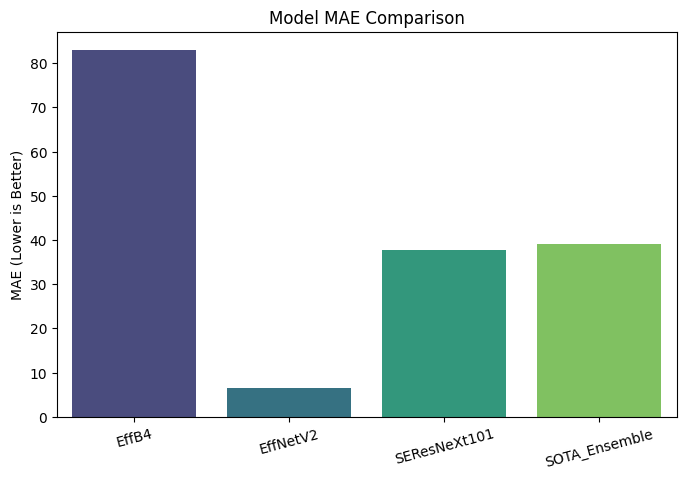

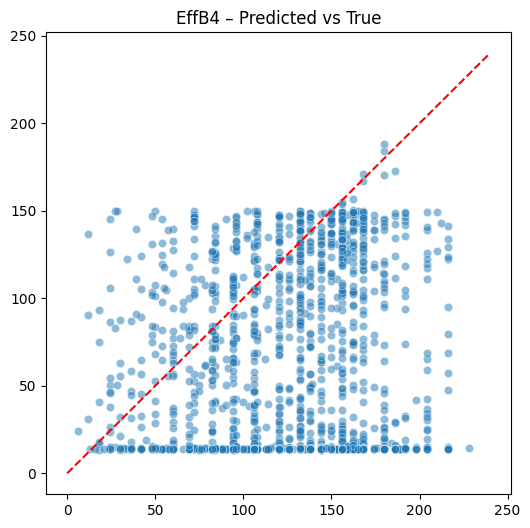

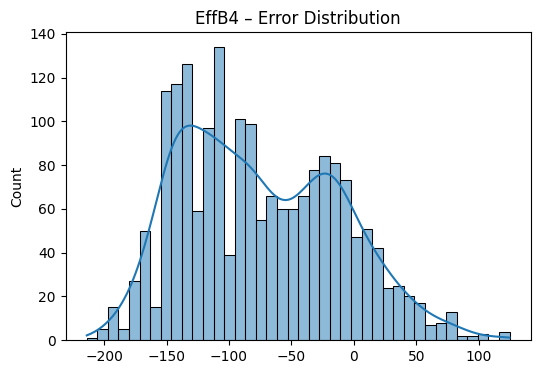

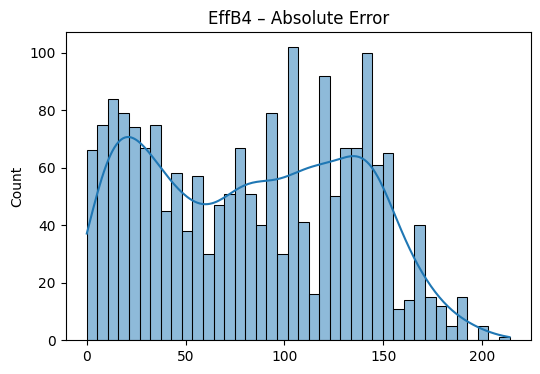

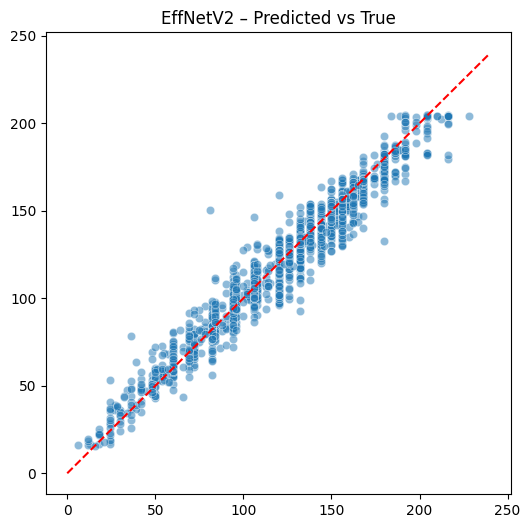

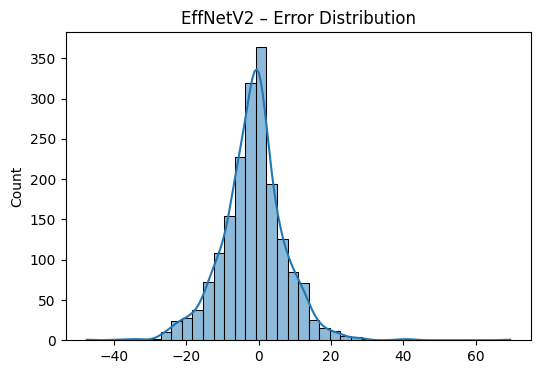

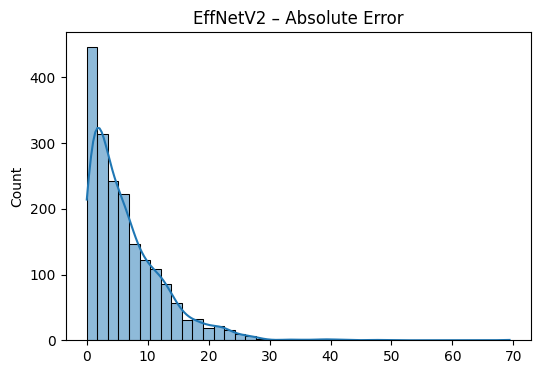

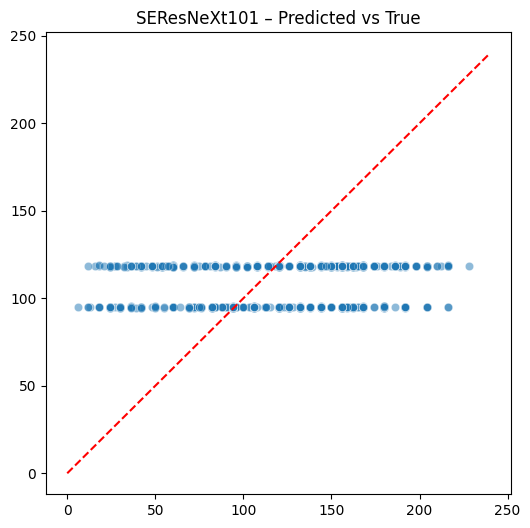

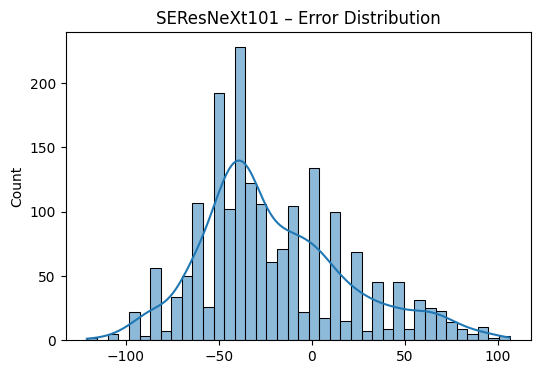

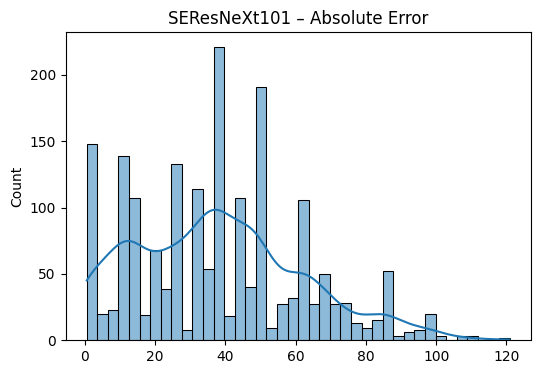

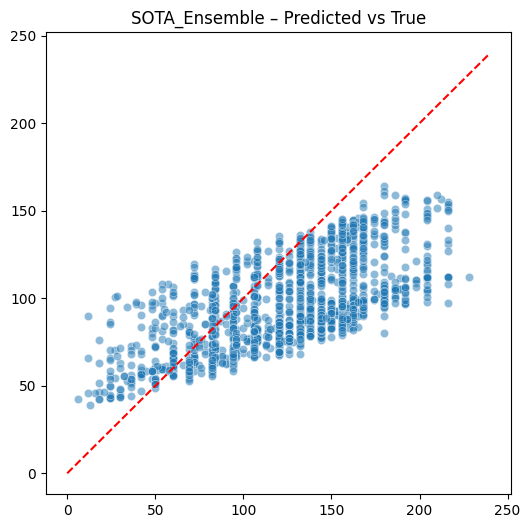

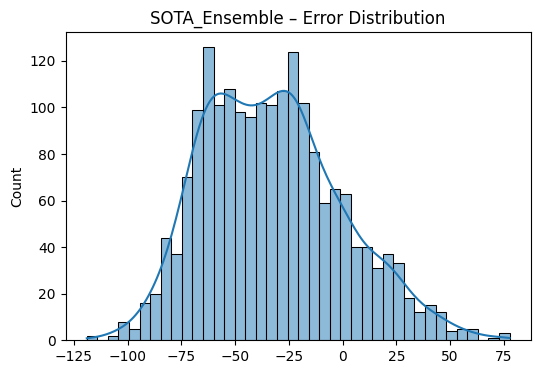

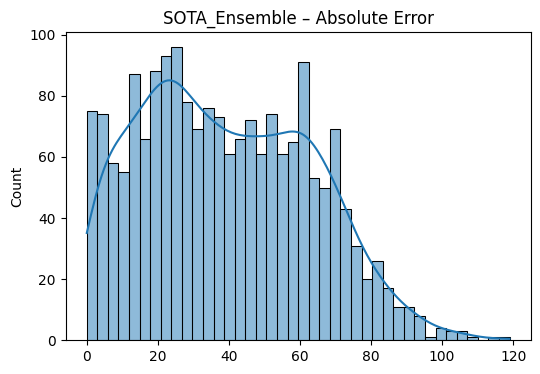

Best model is: EffNetV2 with MAE = 6.4632273
     id     boneage
0  4360  135.029510
1  4361  143.079163
2  4362   54.115398
3  4363  111.993240
4  4364  107.134521
Saved: submission_best_model.csv


In [42]:
# ============================================================
# RSNA BONE AGE – 4 MODEL COMPARISON + VISUALIZATION + BEST MODEL
# ============================================================

import os, cv2, torch, timm
import numpy as np, pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# 1. LOAD TRAINING DATA
# ============================================================

train_csv = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset.csv"
train_img_dir = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset/boneage-training-dataset"

df = pd.read_csv(train_csv)
df["gender"] = df["male"].astype(int)

train_df, val_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["gender"]
)

# ============================================================
# 2. TRANSFORMS
# ============================================================

IMG_SIZE = 384
test_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.ToFloat(max_value=255.0),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

# ============================================================
# 3. DATASET CLASS
# ============================================================

class BoneAgeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None, is_test=False):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        gender = torch.tensor(row["gender"], dtype=torch.long)

        if self.transform:
            img = self.transform(image=img)["image"]

        if self.is_test:
            return img, gender, row["id"]
        else:
            target = torch.tensor(row["boneage"], dtype=torch.float32)
            return img, gender, target

val_dataset = BoneAgeDataset(val_df, train_img_dir, test_tfms)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

# ============================================================
# 4. MODEL CLASS
# ============================================================

class OrdinalModel(nn.Module):
    def __init__(self, backbone_name):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=False, num_classes=0)
        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Sequential(
            nn.Linear(self.backbone.num_features + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 240)
        )

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        logits = self.fc(torch.cat([f, g], dim=1))
        prob = torch.softmax(logits, dim=1)
        months = torch.arange(240, device=logits.device, dtype=torch.float32)
        return (prob * months).sum(dim=1)

# ============================================================
# 5. LOAD MODELS
# ============================================================

models = {
    "EffB4": OrdinalModel("tf_efficientnet_b4_ns").to(device),
    "EffNetV2": OrdinalModel("efficientnetv2_rw_s").to(device),
    "SEResNeXt101": OrdinalModel("seresnext101_32x4d").to(device)
}

models["EffB4"].load_state_dict(torch.load("/kaggle/working/best_effb4_384_25.pth", map_location=device))
models["EffNetV2"].load_state_dict(torch.load("/kaggle/working/best_effnetv2_rw_s.pth", map_location=device))
models["SEResNeXt101"].load_state_dict(torch.load("/kaggle/working/best_model.pth", map_location=device))

for m in models.values():
    m.eval()

# ============================================================
# 6. SOTA ENSEMBLE
# ============================================================

def sota_predict(img, gender, models):
    effb4, effv2, seres = models
    p1 = effb4(img, gender)
    p2 = effv2(img, gender)
    p3 = seres(img, gender)
    return 0.35*p1 + 0.35*p2 + 0.30*p3

# ============================================================
# 7. EVALUATION FUNCTIONS
# ============================================================

def evaluate_single(model, loader):
    preds, targets = [], []
    with torch.no_grad():
        for img, gender, target in loader:
            img = img.to(device)
            gender = gender.to(device)
            pred = model(img, gender)
            preds.extend(pred.cpu().numpy())
            targets.extend(target.numpy())
    preds = np.array(preds)
    targets = np.array(targets)
    return np.mean(np.abs(preds - targets)), preds, targets

def evaluate_sota(models, loader):
    preds, targets = [], []
    with torch.no_grad():
        for img, gender, target in loader:
            img = img.to(device)
            gender = gender.to(device)
            pred = sota_predict(img, gender, models)
            preds.extend(pred.cpu().numpy())
            targets.extend(target.numpy())
    preds = np.array(preds)
    targets = np.array(targets)
    return np.mean(np.abs(preds - targets)), preds, targets

# ============================================================
# 8. EVALUATE ALL 4 MODELS
# ============================================================

results = {}
pred_dict = {}

for name, model in models.items():
    mae, preds, targets = evaluate_single(model, val_loader)
    results[name] = mae
    pred_dict[name] = (preds, targets)
    print(f"{name} MAE:", mae)

sota_mae, sota_preds, sota_targets = evaluate_sota(
    (models["EffB4"], models["EffNetV2"], models["SEResNeXt101"]),
    val_loader
)
results["SOTA_Ensemble"] = sota_mae
pred_dict["SOTA_Ensemble"] = (sota_preds, sota_targets)

print("SOTA Ensemble MAE:", sota_mae)

# ============================================================
# 9. VISUALIZATION
# ============================================================

# MAE Bar Chart
plt.figure(figsize=(8,5))
sns.barplot(x=list(results.keys()), y=list(results.values()), palette="viridis")
plt.title("Model MAE Comparison")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=15)
plt.show()

# Detailed plots for each model
for name, (preds, targets) in pred_dict.items():
    # Pred vs True
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=targets, y=preds, alpha=0.5)
    plt.plot([0,240],[0,240],'r--')
    plt.title(f"{name} – Predicted vs True")
    plt.show()

    # Error distribution
    errors = preds - targets
    plt.figure(figsize=(6,4))
    sns.histplot(errors, bins=40, kde=True)
    plt.title(f"{name} – Error Distribution")
    plt.show()

    # Absolute error
    plt.figure(figsize=(6,4))
    sns.histplot(np.abs(errors), bins=40, kde=True)
    plt.title(f"{name} – Absolute Error")
    plt.show()

# ============================================================
# 10. SELECT BEST MODEL
# ============================================================

best_model_name = min(results, key=results.get)
print("Best model is:", best_model_name, "with MAE =", results[best_model_name])

# ============================================================
# 11. TEST INFERENCE USING BEST MODEL
# ============================================================

test_img_dir = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-test-dataset/boneage-test-dataset"

files = sorted([f for f in os.listdir(test_img_dir) if f.endswith(".png")])
ids = [f.replace(".png", "") for f in files]

test_df = pd.DataFrame({"id": ids, "gender": 0})

test_dataset = BoneAgeDataset(test_df, test_img_dir, test_tfms, is_test=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

test_ids, test_preds = [], []

with torch.no_grad():
    for img, gender, id_val in test_loader:
        img = img.to(device)
        gender = gender.to(device)

        if best_model_name == "SOTA_Ensemble":
            pred = sota_predict(img, gender, (models["EffB4"], models["EffNetV2"], models["SEResNeXt101"]))
        else:
            pred = models[best_model_name](img, gender)

        test_ids.extend(id_val)
        test_preds.extend(pred.cpu().numpy())

submission = pd.DataFrame({"id": test_ids, "boneage": test_preds})
submission = submission.sort_values("id")
submission.to_csv("submission_best_model.csv", index=False)

print(submission.head())
print("Saved: submission_best_model.csv")
